# Exploración de las fuentes de datos — OT Consulting (RH)
**Reto Etapa 1 · Punto A** · Franco Varela Villegas · A01199186 · 17 de noviembre de 2026

Objetivo: recorrer las 7 fuentes de datos que exporta el sistema de RH de OT Consulting (PWA en Firebase), archivo por archivo y columna por columna, para conocer el 100% de los datos recibidos: qué contiene cada campo, qué tan completo está, qué valores toma y cómo se relacionan las tablas.

Herramientas: Python (pandas, matplotlib) y SQL (sqlite3 en memoria) para validar las relaciones entre tablas.

In [1]:
import pandas as pd, numpy as np, sqlite3, warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)
HOY = pd.Timestamp('2026-11-17')   # fecha de corte del análisis
D = '../datos/'   # los Excel no se publican; colócalos en /datos para correr el cuaderno
archivos = {
    'colaboradores': 'Catalogo_Colaboradores.xlsx',
    'asignaciones':  'Asignaciones_Colaboradores.xlsx',
    'clientes':      'Catalogo_Clientes.xlsx',
    'activos':       'Catalogo_Activos.xlsx',
    'matriz':        'Matriz_Habilidades.xlsx',
    'habilidades':   'Catalogo_Habilidades.xlsx',
    'departamentos': 'Catalogo_Departamentos.xlsx',
}
df = {k: pd.read_excel(D + f) for k, f in archivos.items()}
pd.DataFrame({'archivo': archivos.values(),
              'hojas': [pd.ExcelFile(D + f).sheet_names for f in archivos.values()],
              'filas': [d.shape[0] for d in df.values()],
              'columnas': [d.shape[1] for d in df.values()]}, index=archivos.keys())

,archivo,hojas,filas,columnas
colaboradores,Catalogo_Colaboradores.xlsx,[Colaboradores],107,45
asignaciones,Asignaciones_Colaboradores.xlsx,[Asignaciones_Colaboradores],31,11
clientes,Catalogo_Clientes.xlsx,[Clientes_Proyectos],12,13
activos,Catalogo_Activos.xlsx,[Inventario_Activos],123,11
matriz,Matriz_Habilidades.xlsx,[Matriz Habilidades],54,77
habilidades,Catalogo_Habilidades.xlsx,[Habilidades],71,6
departamentos,Catalogo_Departamentos.xlsx,[Departamentos],6,7


**Respuesta:** se importaron los 7 archivos sin errores; cada uno trae una sola hoja. El archivo más ancho es la Matriz de habilidades (77 columnas, una por habilidad) y el más detallado por persona es Colaboradores (45 columnas).

In [2]:
SENSIBLES = {'Nombre Completo','Nombre Colaborador','Colaborador Asignado','Beneficiario','Parentesco','Fecha Nacimiento',
             'Teléfono','Correo Electrónico','Domicilio','RFC','CURP','NSS','Contacto Principal','Email Contacto',
             'PM OTC','PM Cliente','Serie','Alergias/Condiciones','Sueldo Neto IMSS','Sueldo Asimilados/Sindicato',
             'Sueldo Complementos','Sueldo Neto Total','Comisión Nómina','Impuestos IMSS','Sueldo Total Integrado','Costo'}

def perfil(d):
    """Perfil columna por columna: tipo, nulos, únicos, valores de ejemplo, mínimo y máximo.
    En columnas con datos personales o sueldos no se muestran valores (versión pública)."""
    filas = []
    for c in d.columns:
        s = d[c]
        if c.strip() in SENSIBLES:
            filas.append({'columna': c, 'tipo': str(s.dtype), 'nulos': int(s.isna().sum()),
                          '% nulos': round(s.isna().mean() * 100, 1), 'únicos': int(s.nunique()),
                          'ejemplos': '(oculto)', 'mín': '(oculto)', 'máx': '(oculto)', 'texto con espacios': 0})
            continue
        txt = s.dropna().astype(str).str.strip()
        filas.append({
            'columna': c, 'tipo': str(s.dtype),
            'nulos': int(s.isna().sum()), '% nulos': round(s.isna().mean() * 100, 1),
            'únicos': int(s.nunique()),
            'ejemplos': ' | '.join(txt.value_counts().index[:3]),
            'mín': s.min() if s.dtype != object else (txt.min() if len(txt) else None),
            'máx': s.max() if s.dtype != object else (txt.max() if len(txt) else None),
            'texto con espacios': int((s.dropna().astype(str) != txt).sum()) if s.dtype == object else 0,
        })
    return pd.DataFrame(filas)

## 1. Catalogo_Colaboradores.xlsx
Expediente maestro de cada persona: identificación, datos personales (anonimizados), estatus, nómina, sueldos, seguros, beneficiarios y un checklist de documentos.

In [3]:
c = df['colaboradores']
print(c.shape); list(c.columns)

(107, 45)


['ID',
 'Nombre Completo',
 'Género',
 'Fecha Nacimiento',
 'Teléfono',
 'Correo Electrónico',
 'Ciudad',
 'Domicilio',
 'RFC',
 'CURP',
 'NSS',
 'Estatus',
 'Fecha Incorporación',
 'Fecha de Baja',
 'Tipo Nómina',
 'Departamento',
 'Puesto',
 'Sueldo Neto IMSS',
 'Sueldo Asimilados/Sindicato',
 'Sueldo Complementos',
 'Sueldo Neto Total',
 'Comisión Nómina',
 'Impuestos IMSS',
 'Sueldo Total Integrado',
 'SGMM',
 'Seguro Vida',
 'Beneficiario',
 'Parentesco',
 'Porcentaje Beneficiario',
 'Alergias/Condiciones',
 'Notas',
 'Doc: Acta',
 'Doc: INE',
 'Doc: CURP',
 'Doc: Pasaporte',
 'Doc: Visa',
 'Doc: Const. Situación Fiscal',
 'Doc: NSS',
 'Doc: Comprobante Domicilio',
 'Doc: Banco',
 'Doc: Foto',
 'Doc: Contrato',
 'Aviso: Infonavit',
 'Aviso: Manutención',
 'Formato: RH']

In [4]:
perfil(c)

,columna,tipo,nulos,% nulos,únicos,ejemplos,mín,máx,texto con espacios
0,ID,str,0,0.0,107,OTC003 | OTC004 | OTC005,OTC003,OTC110,0
1,Nombre Completo,str,0,0.0,107,(oculto),(oculto),(oculto),0
2,Género,str,0,0.0,2,Masculino | Femenino,Femenino,Masculino,0
3,Fecha Nacimiento,str,1,0.9,104,(oculto),(oculto),(oculto),0
4,Teléfono,int64,0,0.0,1,(oculto),(oculto),(oculto),0
5,Correo Electrónico,str,0,0.0,1,(oculto),(oculto),(oculto),0
6,Ciudad,str,0,0.0,25,Monterrey | Edo de México | CDMX,CDMX,Zacatepec,0
7,Domicilio,str,0,0.0,1,(oculto),(oculto),(oculto),0
8,RFC,str,0,0.0,1,(oculto),(oculto),(oculto),0
9,CURP,str,0,0.0,1,(oculto),(oculto),(oculto),0


In [5]:
# Valores de las columnas categóricas
for col in ['Género','Estatus','Tipo Nómina','Departamento','SGMM','Seguro Vida','Ciudad']:
    print(f'--- {col}'); print(c[col].value_counts(dropna=False).to_dict())

--- Género
{'Masculino': 77, 'Femenino': 30}
--- Estatus
{'Activo': 75, 'Baja': 32}
--- Tipo Nómina
{'SMR': 36, 'MAGNESON-SINDICATO': 20, 'OTC 100%': 18, 'XERES OT-SINDICATO': 10, 'OTC-SINDICATO (SMR)': 10, nan: 6, 'MODALIDAD 40-SMR': 3, 'ADMINISTRATIVA': 2, 'IRAZU/ASIMILADOS': 1, 'EXTRANJERO': 1}
--- Departamento
{nan: 95, 'Operaciones y Soporte': 11, 'Ventas': 1}
--- SGMM
{'METLIFE': 36, 'SEGUROS ATLAS': 24, 'PLAN SEGURO': 15, 'NO': 11, nan: 6, 'SI': 6, 'PLAN SEGUROS': 4, 'PLAN ATLAS': 2, 'PENDIENTE': 1, 'NO LO ENVIO': 1, 'PENDIENTE LLAMAR': 1}
--- Seguro Vida
{'SI': 72, 'NO': 29, nan: 6}
--- Ciudad
{'Monterrey': 50, 'Edo de México': 12, 'CDMX': 12, 'Puebla': 7, 'Tlaxcala': 4, 'Queretaro': 2, 'Cuernavaca': 2, 'Toluca': 1, 'Guadalajara': 1, 'Jalisco': 1, 'Ensenada': 1, 'San Luis Potosí': 1, 'Ciudad Obregón': 1, 'Zacatepec': 1, 'Cananea': 1, 'Tuxtla Gutierrez Chiapas': 1, 'MTY': 1, 'Chihuahua': 1, 'Tamaulipas': 1, 'Matriz Coporativa': 1, 'Hidalgo': 1, 'Mugica, Michoacan': 1, 'Colombia'

In [6]:
# Columnas anonimizadas (un solo valor para todos)
anon = [x for x in c.columns if c[x].nunique() == 1]
print('Columnas con un solo valor:', anon)

Columnas con un solo valor: ['Teléfono', 'Correo Electrónico', 'Domicilio', 'RFC', 'CURP', 'NSS', 'Alergias/Condiciones']


In [7]:
# Validación de fórmulas de sueldo
c['chk_neto'] = (c['Sueldo Neto IMSS'] + c['Sueldo Asimilados/Sindicato'] + c['Sueldo Complementos'] - c['Sueldo Neto Total']).abs() > 1
c['chk_integ'] = (c['Sueldo Neto Total'] + c['Comisión Nómina'] + c['Impuestos IMSS'] - c['Sueldo Total Integrado']).abs() > 1
print('Filas donde Neto Total no cuadra:', c.chk_neto.sum(), '| donde Integrado no cuadra:', c.chk_integ.sum())
c[['Sueldo Neto IMSS','Sueldo Asimilados/Sindicato','Sueldo Neto Total','Sueldo Total Integrado']].describe().loc[['count','mean','50%']].round(0)

Filas donde Neto Total no cuadra: 0 | donde Integrado no cuadra: 0


,Sueldo Neto IMSS,Sueldo Asimilados/Sindicato,Sueldo Neto Total,Sueldo Total Integrado
count,107.0,107.0,107.0,107.0
mean,10770.0,23160.0,35049.0,42005.0
50%,9174.0,21802.0,38500.0,45743.0


In [8]:
# Fechas y estatus
c['inc'] = pd.to_datetime(c['Fecha Incorporación'], errors='coerce')
c['nac'] = pd.to_datetime(c['Fecha Nacimiento'], errors='coerce')
c['baja'] = pd.to_datetime(c['Fecha de Baja'], errors='coerce')
print(pd.crosstab(c.Estatus, c.baja.notna().rename('tiene fecha de baja')))
print('Activos con fecha de baja:', c[(c.Estatus=='Activo') & c.baja.notna()][['ID','Fecha de Baja']].values.tolist())
print('Activos con sueldo 0:', c[(c.Estatus=='Activo') & (c['Sueldo Neto Total']<=0)].ID.tolist())
print('Bajas sin tipo de nómina:', c[c['Tipo Nómina'].isna()].ID.tolist())
print('Puesto PENDIENTE:', (c.Puesto=='PENDIENTE').sum(), '| activos:', ((c.Puesto=='PENDIENTE') & (c.Estatus=='Activo')).sum())
print('Registros FAMILIAR COLABORADOR:', c[c.Puesto=='FAMILIAR COLABORADOR'].ID.tolist())

tiene fecha de baja  False  True 
Estatus                          
Activo                  74      1
Baja                    18     14
Activos con fecha de baja: [['OTC029', '2026-11-19']]
Activos con sueldo 0: ['OTC013', 'OTC043', 'OTC049', 'OTC073', 'OTC080']
Bajas sin tipo de nómina: ['OTC025', 'OTC033', 'OTC052', 'OTC053', 'OTC066', 'OTC070']
Puesto PENDIENTE: 48 | activos: 29
Registros FAMILIAR COLABORADOR: ['OTC108', 'OTC109']


In [9]:
# Checklist de documentos: % de activos con cada documento
docs = [x for x in c.columns if x.startswith(('Doc:','Aviso:','Formato:'))]
ok = ['SI','Planta','Por Proyecto','NO APLICA']
act = c[c.Estatus=='Activo']
cobertura = act[docs].isin(ok).mean().mul(100).round(0).sort_values()
print(cobertura.to_string())
req = [d for d in docs if d not in ('Doc: Pasaporte','Doc: Visa')]
print('\nActivos con expediente completo:', act[req].isin(ok).all(axis=1).sum(), 'de', len(act))

Doc: Pasaporte                   1.0
Doc: Visa                        1.0
Aviso: Manutención              12.0
Aviso: Infonavit                13.0
Doc: Contrato                   19.0
Doc: Foto                       40.0
Doc: Const. Situación Fiscal    71.0
Doc: Comprobante Domicilio      72.0
Doc: INE                        75.0
Doc: NSS                        76.0
Doc: Banco                      76.0
Doc: CURP                       77.0
Doc: Acta                       79.0
Formato: RH                     92.0

Activos con expediente completo: 1 de 75


**Respuestas — Colaboradores**
- 107 registros, `ID` único (OTC003–OTC110): es la llave primaria. 75 activos y 32 bajas.
- RFC, CURP, NSS, correo, teléfono y domicilio vienen anonimizados (un solo valor), así que no se pueden usar.
- Las fórmulas de sueldo cuadran en el 100% de las filas: *Neto Total = IMSS + Asimilados + Complementos* e *Integrado = Neto + Comisión + Impuestos*.
- Faltantes fuertes: `Departamento` (95 vacíos), `Puesto` = «PENDIENTE» (48), `Fecha de Baja` vacía en 18 bajas, `Porcentaje Beneficiario` (104), `Notas` (107).
- Inconsistencias: OTC029 activo con fecha de baja futura, 5 activos con sueldo $0, 2 «FAMILIAR COLABORADOR» dados de alta como empleados, `SGMM` con 11 variantes de texto, ciudades sin estandarizar («MTY» / «Monterrey»).
- Solo 1 de 75 activos tiene el expediente completo; el contrato es el documento que más falta.

## 2. Asignaciones_Colaboradores.xlsx
Relación colaborador → cliente/proyecto, con rol, tipo de asignación y vigencia.

In [10]:
a = df['asignaciones']
perfil(a)

,columna,tipo,nulos,% nulos,únicos,ejemplos,mín,máx,texto con espacios
0,ID Colaborador,str,0,0.0,30,OTC095 | OTC004 | OTC005,OTC004,OTC107,0
1,Nombre Colaborador,str,0,0.0,30,(oculto),(oculto),(oculto),0
2,Nómina/Rol Interno,str,0,0.0,11,PENDIENTE | CONSULTOR FUNCIONAL ORACLE EBS SENIOR | CONS...,CONSULTOR DBA ORACLE SENIOR,PENDIENTE,0
3,Estatus Colaborador,str,0,0.0,1,Activo,Activo,Activo,0
4,Cliente,str,0,0.0,3,METALSA | Allegion | Grupo Daltile,Allegion,METALSA,0
5,Proyecto,str,0,0.0,4,Asignación indefinida | Soporte AMS Manufacta | Migració...,Asignación indefinida,Soporte AMS Manufacta,0
6,Rol Asignado,str,0,0.0,2,PENDIENTE | CONSULTOR FUNCIONAL ORACLE EBS SENIOR,CONSULTOR FUNCIONAL ORACLE EBS SENIOR,PENDIENTE,0
7,Tipo de Asignación,str,0,0.0,2,Proyecto | Asignación,Asignación,Proyecto,0
8,Estatus Asignación,str,0,0.0,1,En Curso,En Curso,En Curso,0
9,Fecha Inicio,str,0,0.0,4,1990-01-01 | 2026-10-13 | 2026-01-01,1990-01-01,2026-10-13,0


In [11]:
print('IDs repetidos:', a[a['ID Colaborador'].duplicated(keep=False)][['ID Colaborador','Cliente','Proyecto','Fecha Inicio']].values.tolist())
print('Fechas de inicio 1990-01-01 (relleno):', (a['Fecha Inicio'].astype(str)=='1990-01-01').sum())
print('Rol asignado PENDIENTE:', (a['Rol Asignado']=='PENDIENTE').sum(), 'de', len(a))
print('Personas asignadas por cliente:', a.groupby(a.Cliente.str.strip())['ID Colaborador'].nunique().to_dict())

IDs repetidos: [['OTC095', 'Grupo Daltile ', 'Marazzi', '2026-01-01'], ['OTC095', 'METALSA', 'Asignación indefinida', '1990-01-01']]
Fechas de inicio 1990-01-01 (relleno): 21
Rol asignado PENDIENTE: 29 de 31
Personas asignadas por cliente: {'Allegion': 5, 'Grupo Daltile': 3, 'METALSA': 23}


**Respuestas — Asignaciones**
- 31 filas de 30 personas: OTC095 está en dos asignaciones a la vez (METALSA y Daltile).
- 21 fechas de inicio con el relleno `1990-01-01` y 24 fechas fin «Indefinido» (texto en una columna de fecha).
- `Rol Asignado` está en «PENDIENTE» en 29 de 31. `Nómina/Rol Interno` repite el `Puesto` del catálogo.
- 23 de los 30 asignados están en METALSA.

## 3. Catalogo_Clientes.xlsx
Clientes y sus proyectos (una fila por proyecto).

In [12]:
cl = df['clientes']
perfil(cl)

,columna,tipo,nulos,% nulos,únicos,ejemplos,mín,máx,texto con espacios
0,Cód Cliente,str,0,0.0,8,C0001 | C0002 | C0003,C0001,C0008,0
1,Cliente,str,0,0.0,8,METALSA | Grupo Daltile | Allegion,Allegion,Rent A Center (RAC Mèxico Operaciones),0
2,Industria,str,0,0.0,5,Manufactura | Automotriz | Consultoría,Automotriz,Rentas de equipo,0
3,RFC,str,8,66.7,4,(oculto),(oculto),(oculto),0
4,Contacto Principal,str,0,0.0,8,(oculto),(oculto),(oculto),0
5,Email Contacto,str,3,25.0,7,(oculto),(oculto),(oculto),0
6,Estatus Cliente,str,0,0.0,1,Activo,Activo,Activo,0
7,Proyecto,str,0,0.0,12,AMS Manufactura | Soporte AMS Manufacta | Asignación ind...,AMS Manufactura,Soporte Oracle Cloud,0
8,Fecha Inicio,str,6,50.0,6,2026-07-15 | 2026-10-13 | 2025-06-01,2021-01-01,2026-10-13,0
9,Fecha Fin,str,9,75.0,3,2026-09-23 | 2028-10-30 | 2026-10-30,2026-09-23,2028-10-30,0


In [13]:
cl[['Cód Cliente','Cliente','Proyecto','Fecha Inicio','Fecha Fin','Estatus Proyecto']].assign(**{'tiene PM OTC': cl['PM OTC'].notna()})

,Cód Cliente,Cliente,Proyecto,Fecha Inicio,Fecha Fin,Estatus Proyecto,tiene PM OTC
0,C0001,METALSA,AMS Manufactura,NaN,NaN,En Curso,False
1,C0001,METALSA,Soporte AMS Manufacta,NaN,NaN,En Curso,False
2,C0001,METALSA,Asignación indefinida,NaN,NaN,Por Iniciar,False
3,C0002,Grupo Daltile,Marazzi,2026-07-15,2026-09-23,En Curso,False
4,C0002,Grupo Daltile,Asignación EBS temporal (3 meses),NaN,NaN,Por Iniciar,True
5,C0002,Grupo Daltile,Asignación Funcional-Técnico (4 meses),NaN,NaN,Por Iniciar,True
6,C0003,Allegion,Migración eBs,2026-10-13,2028-10-30,En Curso,False
7,C0004,CITI,Soporte Oracle Cloud,2025-06-01,NaN,En Curso,True
8,C0005,Parker Servicios de México,Desarrollo de Indicadores,NaN,NaN,Por Iniciar,False
9,C0006,Rent A Center (RAC Mèxico Operaciones),SHINE - Asiganci´ñon de recursos de apoyo,2026-06-30,2026-10-30,En Curso,True


**Respuestas — Clientes**
- 8 clientes (`Cód Cliente` C0001–C0008) y 12 proyectos. El cliente se repite por cada proyecto; **el proyecto no tiene código propio**.
- Faltan RFC (8), fechas de inicio (6) y fin (9), PM OTC (6) y PM cliente (6).
- Texto inconsistente: «Grupo Daltile » con espacio, el mismo PM escrito en mayúsculas y en minúsculas, errores de dedo («Manufacta», «Asiganci´ñon»).

## 4. Catalogo_Activos.xlsx
Inventario de equipo de cómputo y a quién está asignado.

In [14]:
ac = df['activos']
perfil(ac)

,columna,tipo,nulos,% nulos,únicos,ejemplos,mín,máx,texto con espacios
0,Cód Activo,str,0,0.0,123,A0001 | A0002 | A0003,A0001,A0128,0
1,Descripción,str,0,0.0,2,Computadora | Monitor,Computadora,Monitor,0
2,Marca,str,0,0.0,12,DELL | HP | LENOVO,ACER,Lenovo,0
3,Modelo,str,1,0.8,78,Inspiron Business 3520 | V14 G2 ITL | ELITEBOOK 840 G3,Inspirion 3480,ideapad 520S,0
4,Serie,str,0,0.0,123,(oculto),(oculto),(oculto),0
5,Tipo,str,0,0.0,2,Laptop | Monitor,Laptop,Monitor,0
6,Estatus,str,0,0.0,1,Activo,Activo,Activo,0
7,Costo,float64,0,0.0,31,(oculto),(oculto),(oculto),0
8,Colaborador Asignado,str,0,0.0,74,(oculto),(oculto),(oculto),0
9,Fecha Inicio,str,32,26.0,48,1990-01-01 | 2025-08-25 | 2024-10-14,0199-01-01,2026-10-23,0


In [15]:
ac['col'] = ac['Colaborador Asignado'].astype(str).str.strip()
nombres = set(c['Nombre Completo'].str.strip()); bajas = set(c[c.Estatus=='Baja']['Nombre Completo'].str.strip())
print('Marca (sin normalizar):', ac.Marca.value_counts().to_dict())
print('Normalizada:', ac.Marca.str.strip().str.upper().value_counts().to_dict())
print('Costo total:', ac.Costo.sum(), '| equipos con costo 0:', (ac.Costo==0).sum())
print('Sin asignar:', (ac.col=='Sin Asignar').sum())
print('Equipos a nombre de bajas:', ac.col.isin(bajas).sum())
print('Activos sin equipo:', len(set(act['Nombre Completo'].str.strip()) - set(ac.col)))
print('Series duplicadas:', ac.Serie.duplicated().sum())

Marca (sin normalizar): {'DELL': 54, 'HP': 23, 'LENOVO': 17, 'ACER': 8, 'Lenovo': 5, 'DELL ': 4, 'HP ': 3, 'Dell': 3, 'LENOVO ': 2, 'ASUS': 2, 'Dell ': 1, 'Acer': 1}
Normalizada: {'DELL': 62, 'HP': 26, 'LENOVO': 24, 'ACER': 9, 'ASUS': 2}
Costo total: 567915.55 | equipos con costo 0: 70
Sin asignar: 32
Equipos a nombre de bajas: 17
Activos sin equipo: 18
Series duplicadas: 0


**Respuestas — Activos**
- 123 equipos (122 laptops, 1 monitor) con `Cód Activo` único. La relación con el colaborador es **por nombre**, no por ID.
- Costo total capturado $567,915.55, pero 70 equipos tienen costo $0, así que el valor real es mayor.
- `Marca` tiene 12 variantes que en realidad son 6 marcas. `Estatus` siempre «Activo», aunque haya equipos a nombre de bajas (17).
- `Fecha Fin` mezcla fechas con la palabra «Activo»; 35 fechas de inicio con relleno `1990-01-01`.

## 5. Catalogo_Habilidades.xlsx y Matriz_Habilidades.xlsx
Catálogo de 71 habilidades y nivel de cada colaborador en cada una.

In [16]:
h = df['habilidades']; m = df['matriz']
perfil(h)

,columna,tipo,nulos,% nulos,únicos,ejemplos,mín,máx,texto con espacios
0,estatus,str,0,0.0,1,Activo,Activo,Activo,0
1,tecnologia,str,0,0.0,6,Oracle eBS | Plataformas Tecnológicas | Oracle Fusion Cloud,Certificaciones,Plataformas Tecnológicas,0
2,codigo,str,0,0.0,71,H0002 | H0003 | H0004,H0002,S0005,0
3,tipo,str,0,0.0,2,HARD | SOFT,HARD,SOFT,0
4,descripcion,str,0,0.0,58,GL | SLA | CE,!PROC,iEXP,0
5,uid,int64,0,0.0,71,1789777237350 | 1789777249241 | 1789777260964,1789777237350,1790170273816,0


In [17]:
print(h.groupby(['tecnologia','tipo']).size())
print('Descripciones repetidas:', h.descripcion.str.strip().value_counts()[lambda x: x>1].index.tolist())

tecnologia                tipo
Certificaciones           SOFT     1
Idiomas                   SOFT     1
Oracle Fusion Cloud       HARD    17
Oracle eBS                HARD    30
Otros                     SOFT     2
Plataformas Tecnológicas  HARD    20
dtype: int64
Descripciones repetidas: ['GL', 'SLA', 'CE', 'FA', 'PO', 'AP', 'AME', 'AR', 'OM', 'INV', 'CM', 'WMS', 'MFG']


In [18]:
cols_hab = [x for x in m.columns if ' - ' in x and x[:1] in 'HS']
print('Columnas de habilidad en matriz:', len(cols_hab), '| coinciden con catálogo:', set(x.split(' - ')[0] for x in cols_hab) == set(h.codigo))
niveles = {'Básico':1,'Intermedio':2,'Avanzado':3,'Experto':4}
num = m.set_index('ID Colaborador')[cols_hab].apply(lambda s: s.map(niveles))
expertos = (num == 4).sum().sort_values()
print('\nSin expertos:', expertos[expertos==0].index.tolist())
print('Más expertos:', expertos.tail(6).to_dict())
print('Habilidades evaluadas por persona:', num.notna().sum(axis=1).describe().round(1).to_dict())
print('Activos sin matriz:', len(set(act.ID) - set(m['ID Colaborador'])))

Columnas de habilidad en matriz: 71 | coinciden con catálogo: True

Sin expertos: ['S0005 - Manejo de Conflictos ', 'H0028 - TALEO', 'H0035 - TAX', 'H0011 - iEXP', 'H0023 - OPM', 'H0008 - eBTAX', 'S0004 - Empatia ', 'H0045 - MFG', 'H0043 - Landed Cost', 'H0062 - FUSE']
Más expertos: {'H0009 - PO': 10, 'S0002 - CERTIFICADO ORACLE': 12, 'H0068 - Oracle EBS': 12, 'H0055 - REPORTS': 13, 'H0017 - INV': 13, 'H0052 - PLSQL': 16}
Habilidades evaluadas por persona: {'count': 54.0, 'mean': 28.3, 'std': 20.3, 'min': 1.0, '25%': 14.0, '50%': 22.5, '75%': 38.5, 'max': 69.0}
Activos sin matriz: 28


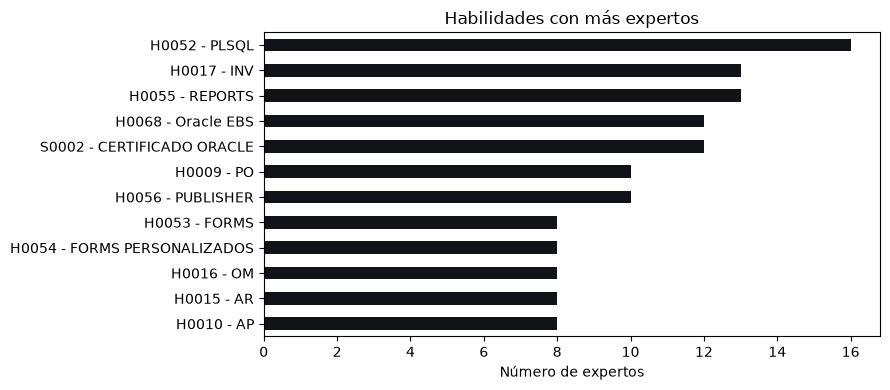

In [19]:
fig, ax = plt.subplots(figsize=(9,4))
expertos.tail(12).plot.barh(ax=ax, color='#111318'); ax.set_title('Habilidades con más expertos'); ax.set_xlabel('Número de expertos')
plt.tight_layout(); plt.show()

**Respuestas — Habilidades**
- El catálogo tiene 71 habilidades (67 HARD, 4 SOFT) y coincide 1 a 1 con las columnas de la matriz.
- 13 descripciones se repiten (GL, AP, PO…) porque existen en EBS y en Cloud; la matriz no lo indica en el nombre de la columna.
- La matriz tiene 54 personas; 28 activos no tienen evaluación. Hay 8 habilidades sin ningún experto (TAX, Taleo, OPM, Landed Cost…).
- `S0002 - CERTIFICADO ORACLE` solo dice «Experto» (12 personas) y no trae la fecha de vencimiento.

## 6. Catalogo_Departamentos.xlsx

In [20]:
dp = df['departamentos']
perfil(dp)

,columna,tipo,nulos,% nulos,únicos,ejemplos,mín,máx,texto con espacios
0,estatus,str,0,0.0,1,Activo,Activo,Activo,0
1,nombre,str,0,0.0,6,Ventas | Administración y Finanzas | Recursos Humanos,Administración y Finanzas,Ventas,0
2,responsable,float64,6,100.0,0,,NaN,NaN,0
3,codigo,str,0,0.0,6,D0001 | D0002 | D0003,D0001,D0006,0
4,uid,int64,0,0.0,6,1789623822518 | 1789623978382 | 1789624127466,1789623822518,1789665380680,0
5,objetivo,str,0,0.0,6,"Conseguir nuevos clientes, dar seguimiento a las oportun...",Administración general de OTC,"Tener el control de los ingresos y egresos de OTC, lleva...",0
6,centroCostos,float64,6,100.0,0,,NaN,NaN,0


**Respuestas — Departamentos:** 6 departamentos con código y objetivo; `responsable` y `centroCostos` están vacíos en los 6. «Recursos Humanos » trae un espacio extra, lo que rompe la unión por texto.

## 7. Relaciones entre tablas (SQL)
Se cargan las tablas a SQLite en memoria para validar la integridad referencial.

In [21]:
con = sqlite3.connect(':memory:')
for k, d in df.items():
    d2 = d.copy(); d2.columns = [x.strip() for x in d2.columns]; d2.to_sql(k, con, index=False)
q = lambda s: pd.read_sql(s, con)
q('''
SELECT 'asignaciones sin colaborador' AS prueba, COUNT(*) AS n FROM asignaciones a
  LEFT JOIN colaboradores c ON a."ID Colaborador" = c.ID WHERE c.ID IS NULL
UNION ALL SELECT 'matriz sin colaborador', COUNT(*) FROM matriz m
  LEFT JOIN colaboradores c ON m."ID Colaborador" = c.ID WHERE c.ID IS NULL
UNION ALL SELECT 'activos colaboradores sin asignación', COUNT(*) FROM colaboradores c
  WHERE c.Estatus='Activo' AND c.ID NOT IN (SELECT "ID Colaborador" FROM asignaciones)
UNION ALL SELECT 'asignaciones con proyecto fuera del catálogo', COUNT(*) FROM asignaciones a
  WHERE TRIM(a.Proyecto) NOT IN (SELECT TRIM(Proyecto) FROM clientes)
UNION ALL SELECT 'equipos con nombre que no existe', COUNT(*) FROM activos ac
  WHERE TRIM(ac."Colaborador Asignado") NOT IN (SELECT TRIM("Nombre Completo") FROM colaboradores)
''')

,prueba,n
0,asignaciones sin colaborador,0
1,matriz sin colaborador,0
2,activos colaboradores sin asignación,45
3,asignaciones con proyecto fuera del catálogo,0
4,equipos con nombre que no existe,32


**Respuesta:** las uniones por ID (Asignaciones y Matriz → Colaboradores) son íntegras. Las uniones por texto funcionan hoy, pero dependen de que el nombre se escriba igual. Los 32 «equipos con nombre que no existe» son los que dicen «Sin Asignar».

## 8. Indicadores iniciales

In [22]:
cont = c[c.inc.dt.year >= 2024]
print('Rotación total:', round((c.Estatus=='Baja').mean()*100,1), '%')
print('Contratados 2024-2026:', len(cont), '| ya se fueron:', (cont.Estatus=='Baja').sum(), f"({(cont.Estatus=='Baja').mean()*100:.0f}%)")
b = c[c.Estatus=='Baja']
print('Antigüedad al salir (años, mediana):', round(((b.baja - b.inc).dt.days/365).median(), 2))
print('Bajas por esquema de nómina:'); print(pd.crosstab(c['Tipo Nómina'].fillna('Sin dato'), c.Estatus))

Rotación total: 29.9 %
Contratados 2024-2026: 55 | ya se fueron: 25 (45%)
Antigüedad al salir (años, mediana): 1.04
Bajas por esquema de nómina:
Estatus              Activo  Baja
Tipo Nómina                      
ADMINISTRATIVA            2     0
EXTRANJERO                0     1
IRAZU/ASIMILADOS          1     0
MAGNESON-SINDICATO       10    10
MODALIDAD 40-SMR          3     0
OTC 100%                 14     4
OTC-SINDICATO (SMR)      10     0
SMR                      29     7
Sin dato                  0     6
XERES OT-SINDICATO        6     4


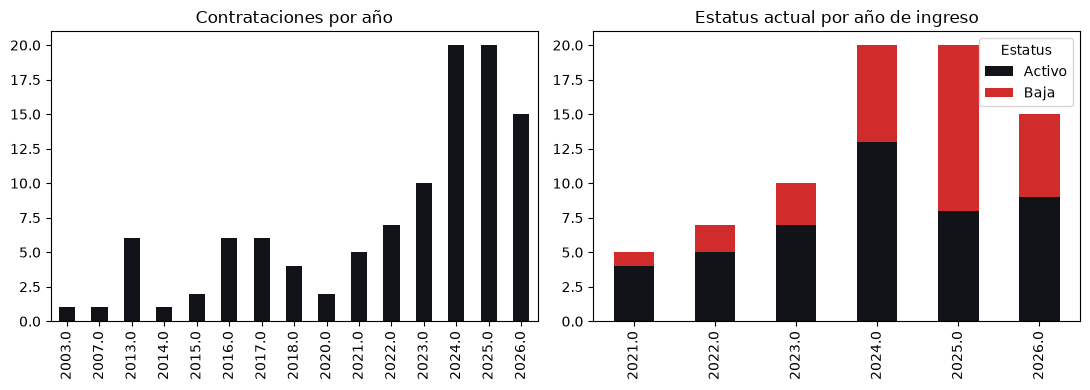

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(11,4))
c.groupby(c.inc.dt.year).ID.count().plot.bar(ax=ax[0], color='#111318'); ax[0].set_title('Contrataciones por año'); ax[0].set_xlabel('')
pd.crosstab(c.inc.dt.year, c.Estatus).loc[2021:].plot.bar(stacked=True, ax=ax[1], color=['#111318','#d22b2b']); ax[1].set_title('Estatus actual por año de ingreso'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

In [24]:
nomina = act[['Sueldo Neto IMSS','Sueldo Asimilados/Sindicato','Sueldo Complementos','Sueldo Neto Total','Comisión Nómina','Impuestos IMSS','Sueldo Total Integrado']].sum()
print('Nómina mensual de activos:'); print(nomina.round(0).to_string())
print('\nCosto por hora estimado (integrado / 160 h) — mediana:', round((act['Sueldo Total Integrado']/160).median(), 0))
print('Asignados:', act.ID.isin(a['ID Colaborador']).sum(), 'de', len(act))

Nómina mensual de activos:
Sueldo Neto IMSS               1002695.0
Sueldo Asimilados/Sindicato    2153691.0
Sueldo Complementos             119786.0
Sueldo Neto Total              3276172.0
Comisión Nómina                 130513.0
Impuestos IMSS                  512180.0
Sueldo Total Integrado         3918864.0

Costo por hora estimado (integrado / 160 h) — mediana: 322.0
Asignados: 30 de 75


**Respuestas — Indicadores**
- La rotación es el hallazgo principal: 30% del total de registros y ≈45% de los contratados desde 2024, con una mediana de 1 año antes de salir. MAGNESON-SINDICATO concentra 10 de las 32 bajas.
- La nómina mensual integrada de los activos es de $3.92 M; el 66% del neto se paga por asimilados/sindicato.
- Solo el 40% de los activos tiene asignación capturada. Sin horas ni tarifas no se puede medir la utilización real.
- Con el sueldo integrado y 160 horas al mes ya se puede estimar el costo por hora de cada consultor (mediana de alrededor de $320/h).